# Report Figures — Gilt PCA Assignment

Generates five charts (rolling idiosyncratic share, loadings biplot, spread decomposition, UK-curve components, rolling UK-DE correlation), each saved as 300 dpi PNG and vector PDF.

**Script notes**



> Run the loader first so `changes_bp.csv` and `levels_aligned.csv` exist in this folder. Inline plots: keep `%matplotlib inline` (added below). Files are also written to disk.

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

In [3]:
# ----------------------------------------------------------------------
# house style
# ----------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "figure.dpi": 110,
})
NAVY="#1F3864"; BLUE="#2E75B6"; TEAL="#3FA796"; AMBER="#E0A458"; RED="#C0504D"; GREY="#7F7F7F"
CMAP={"UK":NAVY,"US":BLUE,"DE":RED,"FR":AMBER,"IT":TEAL,"JP":GREY,"CA":"#9E5FA3"}

In [4]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"./{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"./{name}.pdf", bbox_inches="tight")
    print("saved", name+".png /", name+".pdf")

In [5]:
EVENTS = {
    "2024-10-30": "Reeves Budget",
    "2026-02-26": "Iran war begins",
    "2026-05-08": "Local elections",
    "2026-05-15": "Burnham / worst day",
}

In [6]:
# ======================================================================
# load + helpers
# ======================================================================
ch = pd.read_csv("./changes_bp.csv", index_col=0, parse_dates=True)
lv = pd.read_csv("./levels_aligned.csv", index_col=0, parse_dates=True)
CTRY10 = ["US_10y","UK_10y","DE_10y","FR_10y","IT_10y","JP_10y","CA_10y"]
labels = [c[:2] for c in CTRY10]
uk = labels.index("UK")

In [7]:
def corr_pca(Z):
    C = np.corrcoef(Z, rowvar=False)
    ev, evec = np.linalg.eigh(C); o = np.argsort(ev)[::-1]
    ev, evec = ev[o], evec[:,o]; load = evec*np.sqrt(ev)
    if (load[:,0] < 0).sum() > len(labels)/2: load[:,0]*=-1; evec[:,0]*=-1
    return ev/ev.sum(), load, C

In [8]:
def add_events(ax, txt=True):
    y0,y1=ax.get_ylim(); span=y1-y0
    for d,lab in EVENTS.items():
        x=pd.Timestamp(d); ax.axvline(x,color=GREY,ls="--",lw=1,alpha=.7)
        if txt:
            ax.annotate(lab,(x,y0+0.04*span),xytext=(3,0),textcoords="offset points",
                        rotation=90,va="bottom",ha="left",fontsize=7.5,color=GREY)

In [9]:
# ======================================================================
# FIG 1 - rolling idiosyncratic share (centrepiece)
# ======================================================================
WIN=63; X=ch[CTRY10]
dates=[]; uk_idio=[]; avg_idio=[]
for end in range(WIN,len(X)+1):
    w=X.iloc[end-WIN:end]; Z=((w-w.mean())/w.std(ddof=1)).values
    _,load,_=corr_pca(Z)
    comm=load[:,0]**2
    dates.append(w.index[-1]); uk_idio.append(1-comm[uk]); avg_idio.append((1-comm).mean())
roll=pd.DataFrame({"UK":uk_idio,"avg":avg_idio},index=pd.DatetimeIndex(dates))

saved fig1_rolling_idiosyncratic.png / fig1_rolling_idiosyncratic.pdf


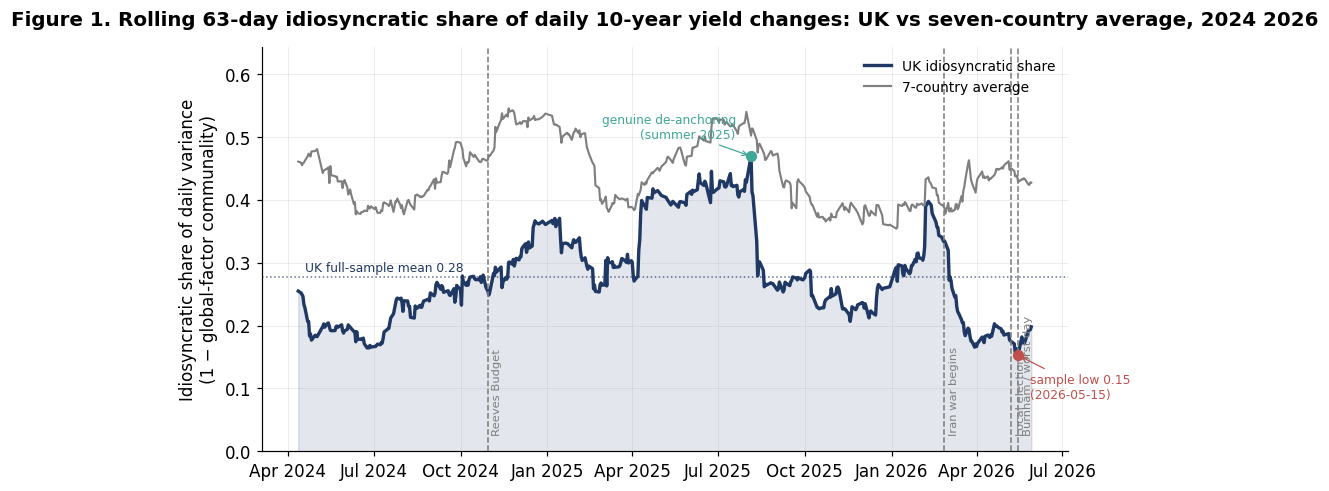

In [12]:
fig,ax=plt.subplots(figsize=(9,4.6))
ax.fill_between(roll.index,roll["UK"],alpha=.12,color=NAVY)
ax.plot(roll.index,roll["UK"],color=NAVY,lw=2.2,label="UK idiosyncratic share")
ax.plot(roll.index,roll["avg"],color=GREY,lw=1.4,ls="-",label="7-country average")
ax.axhline(roll["UK"].mean(),color=NAVY,ls=":",lw=1,alpha=.7)
ax.annotate(f"UK full-sample mean {roll['UK'].mean():.2f}",
            (roll.index[5],roll["UK"].mean()),xytext=(0,4),textcoords="offset points",
            fontsize=8,color=NAVY)
add_events(ax)
# highlight May-2026 trough and summer-2025 peak
trough=roll["UK"].idxmin(); peak=roll.loc["2025-05":"2025-09","UK"].idxmax()
ax.scatter([trough],[roll["UK"].min()],color=RED,zorder=5,s=40)
ax.annotate(f"sample low {roll['UK'].min():.2f}\n({trough.date()})",(trough,roll['UK'].min()),
            xytext=(8,-28),textcoords="offset points",fontsize=8,color=RED,
            arrowprops=dict(arrowstyle="->",color=RED,lw=.8))
ax.scatter([peak],[roll.loc[peak,'UK']],color=TEAL,zorder=5,s=40)
ax.annotate(f"genuine de-anchoring\n(summer 2025)",(peak,roll.loc[peak,'UK']),
            xytext=(-10,12),textcoords="offset points",fontsize=8,color=TEAL,ha="right",
            arrowprops=dict(arrowstyle="->",color=TEAL,lw=.8))
ax.set_ylabel("Idiosyncratic share of daily variance\n(1 \u2212 global-factor communality)")
ax.set_ylim(0,roll[["UK","avg"]].max().max()*1.18)
add_events(ax)
ax.set_title("Figure 1. Rolling 63-day idiosyncratic share of daily 10-year yield changes: UK vs seven-country average, 2024 2026",pad=14)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper right",frameon=False,fontsize=9)
save(fig,"fig1_rolling_idiosyncratic")

saved fig2_loadings_biplot.png / fig2_loadings_biplot.pdf


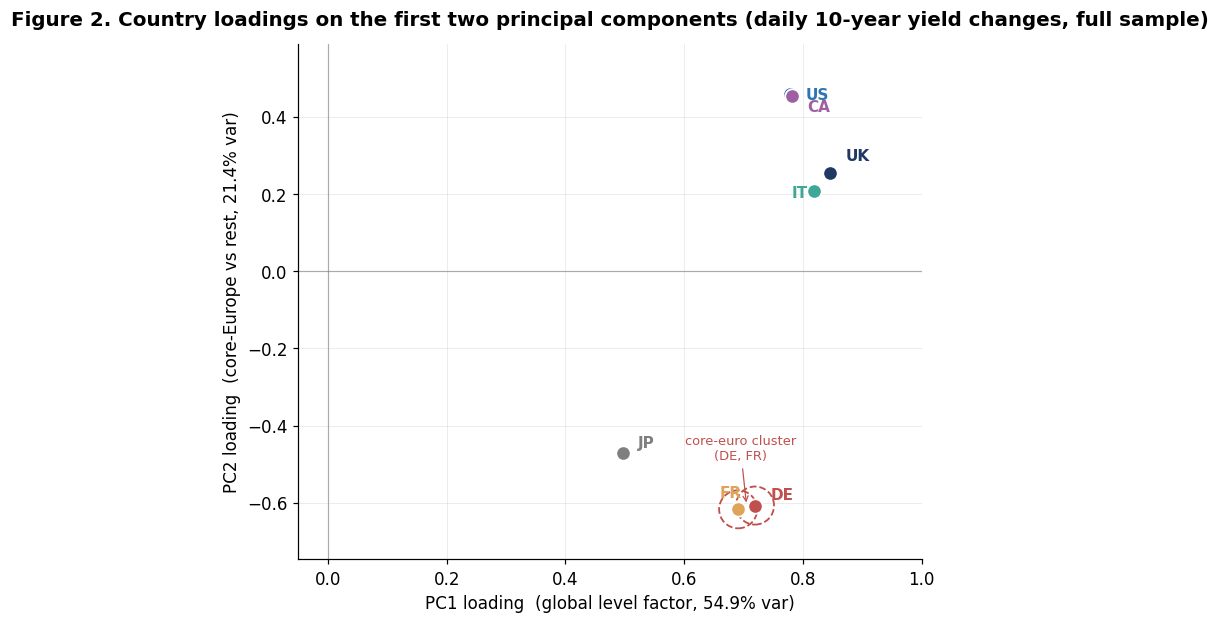

In [13]:
# ======================================================================
# FIG 2 - loadings biplot (PC1 x PC2)
# ======================================================================
Zf=((X-X.mean())/X.std(ddof=1)).values
_,loadF,_=corr_pca(Zf)
fig,ax=plt.subplots(figsize=(6.8,5.8))
ax.axhline(0,color=GREY,lw=.8,alpha=.6); ax.axvline(0,color=GREY,lw=.8,alpha=.6)
# manual label offsets (points) to avoid collisions
off={"US":(10,-4),"UK":(10,8),"DE":(10,4),"FR":(-12,8),"IT":(-14,-4),"JP":(10,4),"CA":(10,-10)}
for i,lab in enumerate(labels):
    x,y=loadF[i,0],loadF[i,1]
    ax.scatter(x,y,s=90,color=CMAP[lab],edgecolor="white",lw=1.2,zorder=3)
    dx,dy=off.get(lab,(8,4))
    ax.annotate(lab,(x,y),xytext=(dx,dy),textcoords="offset points",
                fontsize=10,fontweight="bold",color=CMAP[lab],zorder=4)
euro=[labels.index(c) for c in ["DE","FR"]]
ax.scatter(loadF[euro,0],loadF[euro,1],s=620,facecolor="none",edgecolor=RED,
           lw=1.2,ls="--",zorder=2)
ax.annotate("core-euro cluster\n(DE, FR)",(loadF[euro,0].mean(),loadF[euro,1].max()),
            xytext=(-4,30),textcoords="offset points",fontsize=8.5,color=RED,ha="center",
            arrowprops=dict(arrowstyle="->",color=RED,lw=.8))
ax.set_xlabel("PC1 loading  (global level factor, 54.9% var)")
ax.set_ylabel("PC2 loading  (core-Europe vs rest, 21.4% var)")
ax.set_title("Figure 2. Country loadings on the first two principal components (daily 10-year yield changes, full sample)",pad=12)
ax.set_xlim(-0.05, 1.0); ax.margins(y=0.12)
save(fig,"fig2_loadings_biplot")

In [14]:
# ======================================================================
# FIG 3 - spread widening decomposition (10y & 30y)
# ======================================================================
def widening(tenor):
    uk_=lv[f"UK_{tenor}"]; de=lv[f"DE_{tenor}"]; us=lv[f"US_{tenor}"]
    ukde=(uk_-de)*100; usde=(us-de)*100
    pre=slice("2026-01-01","2026-02-25"); may=slice("2026-05-01","2026-05-29")
    d_ukde=ukde[may].max()-ukde[pre].mean()
    d_usde=usde[may].max()-usde[pre].mean()
    return d_usde, d_ukde-d_usde   # shared, uk-specific
shared10,spec10=widening("10y"); shared30,spec30=widening("30y")

saved fig3_spread_decomposition.png / fig3_spread_decomposition.pdf


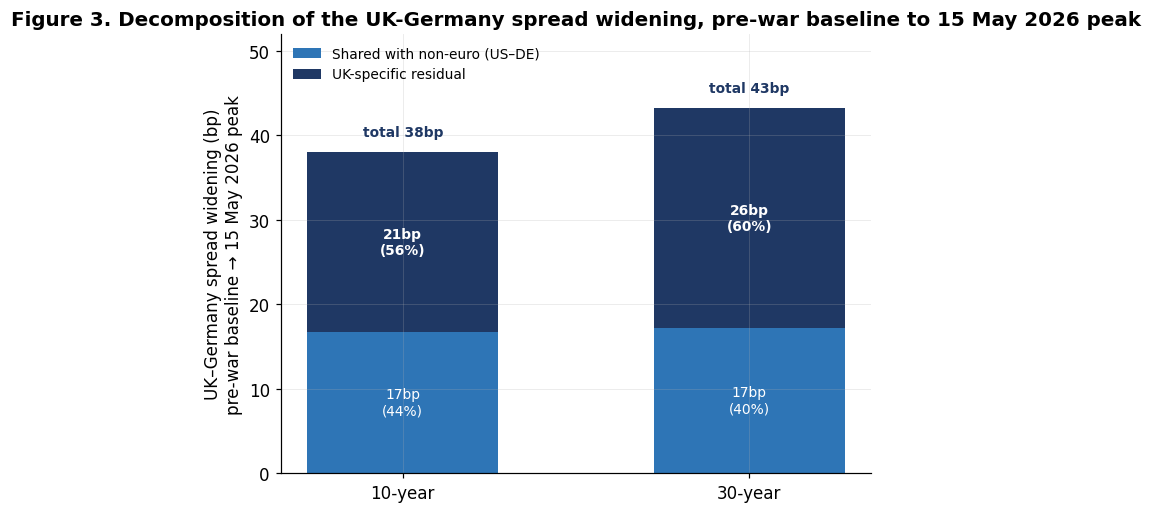

In [15]:
fig,ax=plt.subplots(figsize=(6.4,4.8))
x=[0,1]; w=.55
ax.bar(x,[shared10,shared30],w,label="Shared with non-euro (US\u2013DE)",color=BLUE)
ax.bar(x,[spec10,spec30],w,bottom=[shared10,shared30],label="UK-specific residual",color=NAVY)
for xi,(s,sp) in zip(x,[(shared10,spec10),(shared30,spec30)]):
    tot=s+sp
    ax.text(xi,s/2,f"{s:.0f}bp\n({s/tot*100:.0f}%)",ha="center",va="center",color="white",fontsize=9)
    ax.text(xi,s+sp/2,f"{sp:.0f}bp\n({sp/tot*100:.0f}%)",ha="center",va="center",color="white",fontsize=9,fontweight="bold")
    ax.text(xi,tot+1.5,f"total {tot:.0f}bp",ha="center",va="bottom",fontsize=9,color=NAVY,fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(["10-year","30-year"])
ax.set_ylabel("UK\u2013Germany spread widening (bp)\npre-war baseline \u2192 15 May 2026 peak")
ax.set_title("Figure 3. Decomposition of the UK-Germany spread widening, pre-war baseline to 15 May 2026 peak")
ax.legend(loc="upper left",frameon=False,fontsize=9)
ax.set_ylim(0,(shared30+spec30)*1.2)
save(fig,"fig3_spread_decomposition")

In [16]:
# ======================================================================
# FIG 4 - UK curve move: level / slope / curvature
# ======================================================================
MAT=["UK_2y","UK_5y","UK_10y","UK_30y"]; mats=[2,5,10,30]
Xc=ch[MAT]; S=np.cov(Xc.values,rowvar=False)
ev,evec=np.linalg.eigh(S); o=np.argsort(ev)[::-1]; ev,evec=ev[o],evec[:,o]
if (evec[:,0]<0).sum()>2: evec[:,0]*=-1
if evec[0,1]>evec[-1,1]: evec[:,1]*=-1
if (evec[0,2]+evec[-1,2])<0: evec[:,2]*=-1
move=Xc.loc["2026-05-01":"2026-05-15"].sum().values
proj=evec[:,:3].T@move; share=proj**2/ (proj**2).sum()

saved fig4_curve_components.png / fig4_curve_components.pdf


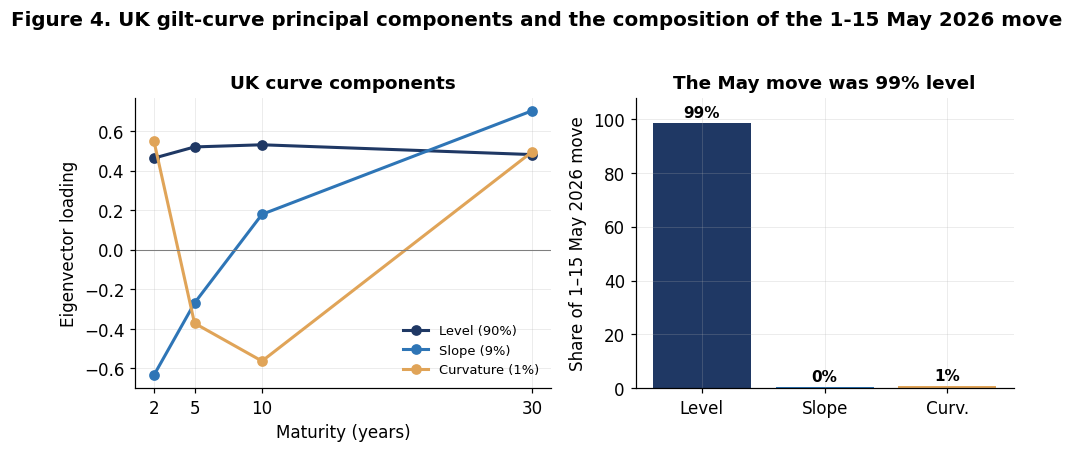

In [17]:
fig,axes=plt.subplots(1,2,figsize=(9,4),gridspec_kw={"width_ratios":[1.1,1]})
# left: component shapes
axc=axes[0]
for k,(nm,col) in enumerate(zip(["Level","Slope","Curvature"],[NAVY,BLUE,AMBER])):
    axc.plot(mats,evec[:,k],marker="o",color=col,lw=2,label=f"{nm} ({ev[k]/ev.sum()*100:.0f}%)")
axc.axhline(0,color=GREY,lw=.7); axc.set_xticks(mats)
axc.set_xlabel("Maturity (years)"); axc.set_ylabel("Eigenvector loading")
axc.set_title("UK curve components",fontsize=12)
axc.legend(frameon=False,fontsize=8.5)
# right: May move composition
axb=axes[1]
bars=axb.bar(["Level","Slope","Curv."],share*100,color=[NAVY,BLUE,AMBER])
for b,s in zip(bars,share*100):
    axb.text(b.get_x()+b.get_width()/2,s+1,f"{s:.0f}%",ha="center",va="bottom",fontsize=10,fontweight="bold")
axb.set_ylabel("Share of 1\u201315 May 2026 move")
axb.set_title("The May move was 99% level",fontsize=12)
axb.set_ylim(0,108)
fig.suptitle("Figure 4. UK gilt-curve principal components and the composition of the 1-15 May 2026 move",
             fontsize=13,fontweight="bold",y=1.02)
save(fig,"fig4_curve_components")

saved fig5_rolling_uk_de_corr.png / fig5_rolling_uk_de_corr.pdf


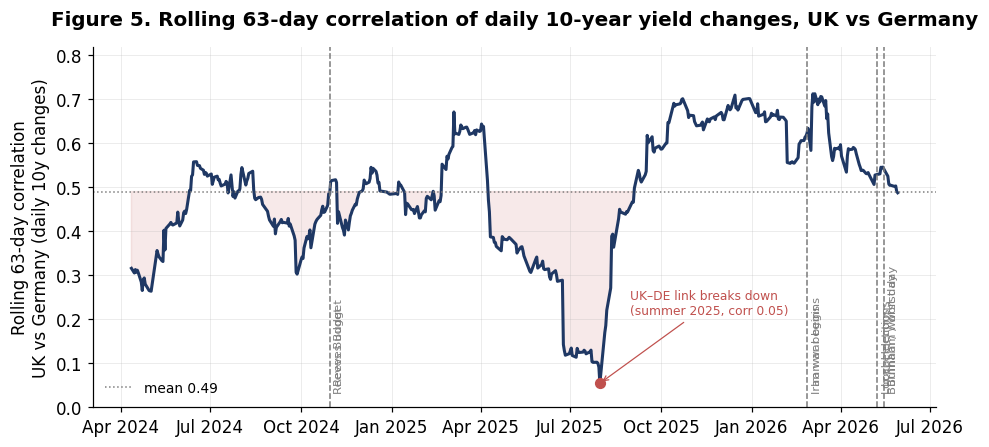

In [18]:
# ======================================================================
# FIG 5 - rolling UK-DE correlation
# ======================================================================
de=labels.index("DE")
dates=[]; ukde_corr=[]
for end in range(WIN,len(X)+1):
    w=X.iloc[end-WIN:end]; C=np.corrcoef(w.values,rowvar=False)
    dates.append(w.index[-1]); ukde_corr.append(C[uk,de])
rc=pd.Series(ukde_corr,index=pd.DatetimeIndex(dates))
fig,ax=plt.subplots(figsize=(9,4.2))
ax.plot(rc.index,rc.values,color=NAVY,lw=2)
ax.fill_between(rc.index,rc.values,rc.mean(),where=(rc.values<rc.mean()),
                color=RED,alpha=.12)
ax.axhline(rc.mean(),color=GREY,ls=":",lw=1,label=f"mean {rc.mean():.2f}")
add_events(ax)
lowdate=rc.loc["2025-05":"2025-09"].idxmin()
ax.scatter([lowdate],[rc.loc[lowdate]],color=RED,zorder=5,s=40)
ax.annotate(f"UK\u2013DE link breaks down\n(summer 2025, corr {rc.loc[lowdate]:.2f})",
            (lowdate,rc.loc[lowdate]),xytext=(20,45),textcoords="offset points",
            fontsize=8,color=RED,arrowprops=dict(arrowstyle="->",color=RED,lw=.8))
ax.set_ylabel("Rolling 63-day correlation\nUK vs Germany (daily 10y changes)")
ax.set_ylim(0, rc.max()*1.15)
add_events(ax)
ax.set_title("Figure 5. Rolling 63-day correlation of daily 10-year yield changes, UK vs Germany",pad=14)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="lower left",frameon=False,fontsize=9)
save(fig,"fig5_rolling_uk_de_corr")

saved fig6_garch_condvol.png / fig6_garch_condvol.pdf


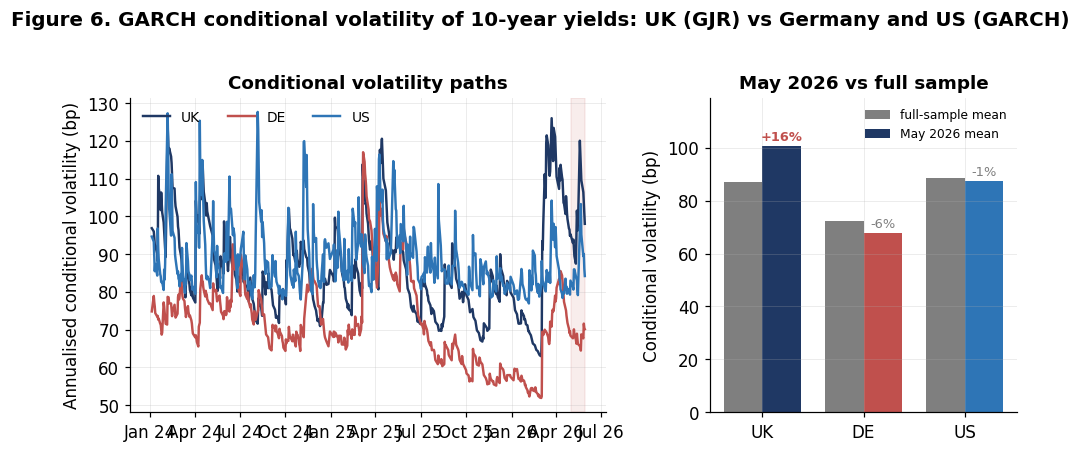

In [19]:
# ======================================================================
# FIG 6 - GARCH conditional volatility (UK asymmetry vs peers)
# ======================================================================
import warnings; warnings.filterwarnings("ignore")
from arch import arch_model

VOL = ["UK_10y", "DE_10y", "US_10y"]
def fit_garch(y, asym):
    o = 1 if asym else 0
    return arch_model(y, mean="Constant", vol="GARCH", p=1, o=o, q=1, dist="t").fit(disp="off")

# UK uses GJR (asymmetric, preferred by AIC); peers use symmetric GARCH
fits = {"UK": fit_garch(ch["UK_10y"].dropna(), True),
        "DE": fit_garch(ch["DE_10y"].dropna(), False),
        "US": fit_garch(ch["US_10y"].dropna(), False)}
cv = pd.DataFrame({k: f.conditional_volatility*np.sqrt(252) for k,f in fits.items()},
                  index=ch.index)

fig,axes=plt.subplots(1,2,figsize=(9,4),gridspec_kw={"width_ratios":[1.55,1]})
# left: conditional-vol paths
axp=axes[0]
for k in ["UK","DE","US"]:
    axp.plot(cv.index,cv[k],color=CMAP[k],lw=1.6,label=k)
axp.axvspan(pd.Timestamp("2026-05-01"),pd.Timestamp("2026-05-29"),color=RED,alpha=.10)
axp.set_ylabel("Annualised conditional volatility (bp)")
axp.set_title("Conditional volatility paths",fontsize=12)
axp.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axp.legend(frameon=False,fontsize=9,ncol=3,loc="upper left")
# right: May-2026 vs full-sample mean (shows the UK-specific spike)
axb=axes[1]
full=cv.mean(); may=cv.loc["2026-05-01":"2026-05-29"].mean()
xpos=np.arange(3); w=.38
axb.bar(xpos-w/2,[full[k] for k in ["UK","DE","US"]],w,color=GREY,label="full-sample mean")
axb.bar(xpos+w/2,[may[k] for k in ["UK","DE","US"]],w,
        color=[CMAP[k] for k in ["UK","DE","US"]],label="May 2026 mean")
for i,k in enumerate(["UK","DE","US"]):
    pct=(may[k]/full[k]-1)*100
    axb.text(i+w/2,may[k]+1,f"{pct:+.0f}%",ha="center",va="bottom",fontsize=8.5,
             fontweight=("bold" if k=="UK" else "normal"),
             color=(RED if k=="UK" else GREY))
axb.set_xticks(xpos); axb.set_xticklabels(["UK","DE","US"])
axb.set_ylabel("Conditional volatility (bp)")
axb.set_title("May 2026 vs full sample",fontsize=12)
axb.legend(frameon=False,fontsize=8)
axb.set_ylim(0, max(may.max(),full.max())*1.18)
fig.suptitle("Figure 6. GARCH conditional volatility of 10-year yields: UK (GJR) vs Germany and US (GARCH)",
             fontsize=13,fontweight="bold",y=1.02)
save(fig,"fig6_garch_condvol")


In [20]:
print("\nAll five figures written (PNG @300dpi + PDF vector).")


All five figures written (PNG @300dpi + PDF vector).
